# **VoxCity Demo**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kunifujiwara/VoxCity/blob/main/docs/examples/demo_quickstart.ipynb)

Build a 3D city from open map data, then simulate sunlight and views. No Python, no account.

Run the cells in order: click ▶, or press **Shift + Enter**. Choose **2.1** or **2.2**, not both.

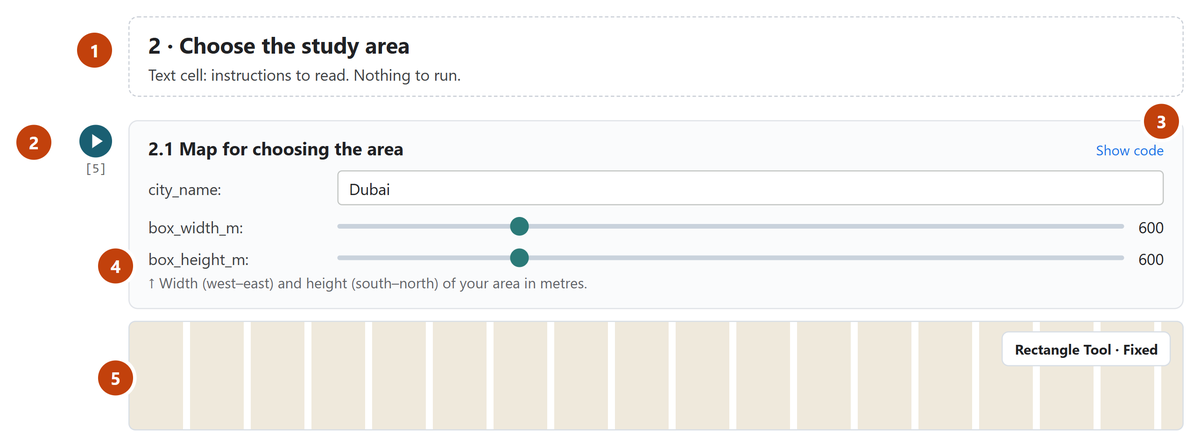

## 1 · Set-up

In [ ]:
#@title 1.1 Install VoxCity (1–2 minutes) { display-mode: "form" }
!pip install -q voxcity

## 2 · Choose the area
Run **2.1**. On the map: click **Fixed**, then click the centre of your street.

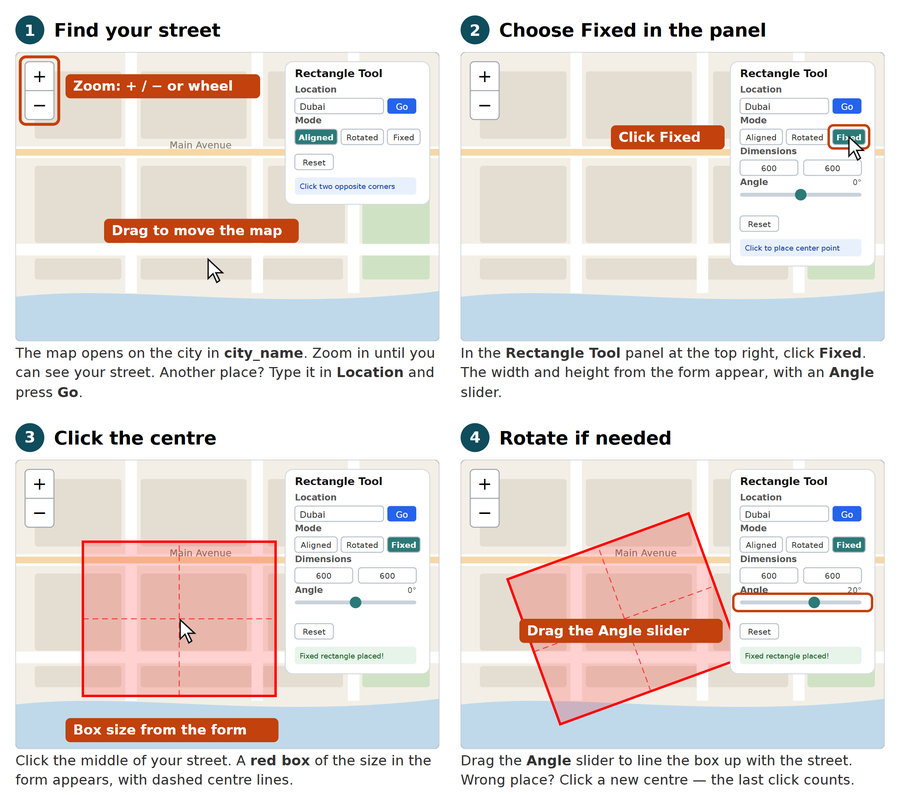

In [ ]:
#@title 2.1 Map for choosing the area { display-mode: "form" }
city_name = "New York"  #@param {type:"string"}
box_width_m = 500  #@param {type:"slider", min:200, max:1500, step:50}
box_height_m = 500  #@param {type:"slider", min:200, max:1500, step:50}
from voxcity.geoprocessor.draw import create_rectangle_map
ui, rectangle_vertices = create_rectangle_map(city_name, zoom=15, width=box_width_m, height=box_height_m)
ui

In [ ]:
#@title 2.2 (Alternative) Type the corners of the area { display-mode: "form" }
#@markdown Only if the map does not work. Longitude and latitude of the south-west and north-east corners.
west = -74.0160  #@param {type:"number"}
south = 40.7033  #@param {type:"number"}
east = -74.0100  #@param {type:"number"}
north = 40.7078  #@param {type:"number"}
rectangle_vertices = [(west, south), (west, north), (east, north), (east, south)]

## 3 · Build the 3D city

In [ ]:
#@title 3.1 Build the 3D city (1–5 minutes) { display-mode: "form" }
cube_size_m = 5  #@param {type:"slider", min:2, max:10, step:1}
from voxcity.generator import get_voxcity
voxcity = get_voxcity(rectangle_vertices, cube_size_m)

## 4 · Look at your city

In [ ]:
#@title 4.1 3D view { display-mode: "form" }
from voxcity.visualizer import visualize_voxcity
visualize_voxcity(voxcity, mode="interactive", downsample=1)

## 5 · Export
OBJ: Blender, Rhino, Twinmotion · INX: ENVI-met · VOX: MagicaVoxel

In [ ]:
#@title 5.1 OBJ file { display-mode: "form" }
from voxcity.exporter.obj import export_obj
export_obj(voxcity, "output/obj", "voxcity")

In [ ]:
#@title 5.2 INX file for ENVI-met { display-mode: "form" }
from voxcity.exporter.envimet import export_inx
export_inx(voxcity, "output/envimet", "voxcity")

In [ ]:
#@title 5.3 VOX file for MagicaVoxel { display-mode: "form" }
from voxcity.exporter.magicavoxel import export_magicavoxel_vox
export_magicavoxel_vox(voxcity, "output/magicavoxel")

In [ ]:
#@title 5.4 Download everything as one zip file { display-mode: "form" }
import shutil
from google.colab import files
files.download(shutil.make_archive("voxcity_output", "zip", "output"))

## 6 · Simulations

In [ ]:
#@title 6.1 Sunlight at street level { display-mode: "form" }
date = "2026-06-21"  #@param {type:"date"}
hour = 15  #@param {type:"slider", min:6, max:19, step:1}
from voxcity.simulator.solar import get_global_solar_irradiance_using_epw
solar_grid = get_global_solar_irradiance_using_epw(
    voxcity,
    calc_type="instantaneous",
    calc_time=f"{date[5:]} {hour:02d}:00:00",   # "MM-DD HH:MM:SS"
    download_nearest_epw=True,
    view_point_height=1.5,
    colormap="magma",
)

In [ ]:
#@title 6.2 Sky view or green view index { display-mode: "form" }
what = "Sky"  #@param ["Sky", "Greenery"]
from voxcity.simulator.visibility import get_view_index
if what == "Sky":
    view_grid = get_view_index(voxcity, mode="sky", view_point_height=1.5, colormap="BuPu_r", elevation_min_degrees=0)
else:
    view_grid = get_view_index(voxcity, mode="green", view_point_height=1.5, colormap="viridis")

## Next steps
[More tutorials](index.md) · [Questions](https://github.com/kunifujiwara/VoxCity/discussions) · [Cite the paper](https://doi.org/10.1016/j.compenvurbsys.2025.102366)